## 1、ModelCallLimitMiddleware中间件

限制模型调用次数，避免无限循环，控制调用成本。

```
ModelCallLimitMiddleware(
  self,
  *,
  thread_limit: int | None = None,
  run_limit: int | None = None,
  exit_behavior: Literal['end', 'error'] = 'end'
)
```

### 1.1 举例1：整个会话限制-优雅退出

In [ ]:
import os
from typing import List

from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.chat_models import init_chat_model
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage, ToolMessage
from langgraph.checkpoint.memory import InMemorySaver

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL")
)

agent = create_agent(
    model=model,
    checkpointer=InMemorySaver(),
    tools=[],
    middleware=[
        ModelCallLimitMiddleware(
            thread_limit=2, # 每个线程最多两次模型调用
            exit_behavior="end" # 达到限制后退出
        )
    ]
)

def pretty_msg(messages: List[SystemMessage | HumanMessage | AIMessage | ToolMessage]):
    for message in messages:
        message.pretty_print()

config = {"configurable": {"thread_id": 1}}
response_first = agent.invoke({
    "messages": [HumanMessage("你好")]},
    config=config
)
print("=" * 30, "> first <", "=" * 30)
pretty_msg(response_first["messages"])
response_second = agent.invoke({
    "messages": [HumanMessage("你是谁？")]},
    config=config
)
print("=" * 30, "> second <", "=" * 30)
pretty_msg(response_second["messages"])
response_third = agent.invoke({
    "messages": [HumanMessage("你能帮我做什么？")]},
    config=config
)
print("=" * 30, "> third <", "=" * 30)
pretty_msg(response_third["messages"])

### 1.2 举例2: 整个会话限制-抛遗传

In [ ]:
import os
from typing import List

from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.chat_models import init_chat_model
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage, ToolMessage
from langgraph.checkpoint.memory import InMemorySaver

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL")
)

agent = create_agent(
    model=model,
    checkpointer=InMemorySaver(),
    tools=[],
    middleware=[
        ModelCallLimitMiddleware(
            thread_limit=2, # 每个线程最多两次模型调用
            exit_behavior="error" # 达到限制后退出
        )
    ]
)

def pretty_msg(messages: List[SystemMessage | HumanMessage | AIMessage | ToolMessage]):
    for message in messages:
        message.pretty_print()

config = {"configurable": {"thread_id": 1}}
response_first = agent.invoke({
    "messages": [HumanMessage("你好")]},
    config=config
)
print("=" * 30, "> first <", "=" * 30)
pretty_msg(response_first["messages"])
response_second = agent.invoke({
    "messages": [HumanMessage("你是谁？")]},
    config=config
)
print("=" * 30, "> second <", "=" * 30)
pretty_msg(response_second["messages"])
response_third = agent.invoke({
    "messages": [HumanMessage("你能帮我做什么？")]},
    config=config
)
print("=" * 30, "> third <", "=" * 30)
pretty_msg(response_third["messages"])

### 1.3 举例3: 单次调用限制-优雅退出

需要fake-server重复触发工具调用，代码如下

In [ ]:
import json
import random
import time
from http.server import BaseHTTPRequestHandler, HTTPServer

class FakeDeepSeekHandler(BaseHTTPRequestHandler):
    def do_POST(self):
        content_length = int(self.headers.get("Content-Length", 0))
        raw_body = self.rfile.read(content_length).decode("utf-8")
        print("\n" + "=" * 100)
        json_body = None

        try:
            json_body = json.loads(raw_body)
            print("[JSON BODY]")
            print(json.dumps(json_body, ensure_ascii=False, indent=2))
        except Exception as e:
            print("[JSON PARSE ERROR]")
            print(repr(e))

        response = {
            "id": "chatcmpl-test",
            "object": "chat.completion",
            "created": int(time.time()),
            "model": "any",
            "choices": [
                {
                    "index": 0,
                    "message": {
                        "role": "assistant",
                        "content": "",
                        "tool_calls": [
                            {
                            "id": "call_1",
                            "type": "function",
                            "function": {
                                "name": json_body["tools"][0]["function"]["name"],
                                "arguments": json.dumps(
                                        {'name': 'xxx', 'email':'123456@qq.com', 'phone': '12345678912'},
                                        ensure_ascii=False
                                    )
                                }
                            }
                        ]
                    },
                    "finish_reason": "stop"
                }
            ],
            "usage": {
                "prompt_tokens": 1,
                "completion_tokens": 1,
                "total_tokens": 2
            }
        }

        append_val = {
            "id": "call_2",
            "type": "function",
            "function": {
                "name": json_body["tools"][1]["function"]["name"],
                "arguments": json.dumps(
                    {'event_name': '问数项目启动会', 'date': '2026-03-27'},
                    ensure_ascii=False
                )
            }
        }

        if random.randint(1, 10) > 2:
            response["choices"][0]["message"]["tool_calls"].append(append_val)

        print("\n" + "=" * 100)
        print("[RESPONSE]")
        print(json.dumps(response, ensure_ascii=False, indent=2))
        body = json.dumps(response, ensure_ascii=False).encode("utf-8")
        self.send_response(200)
        self.send_header("Content-Type", "application/json; charset=utf-8")
        self.send_header("Content-Length", str(len(body)))
        self.end_headers()
        self.wfile.write(body)

    def log_message(self, format, *args):
        pass

def main():
    server = HTTPServer(("127.0.0.1", 8889), FakeDeepSeekHandler)
    print("Fake DeepSeek server running at http://127.0.0.1:8889")
    server.serve_forever()

if __name__ == "__main__":
    main()

客户端代码

In [ ]:
from typing import Union
from pydantic import Field, BaseModel, SecretStr

from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver

load_dotenv(override=True)

model = init_chat_model(
    model="any",
    model_provider="deepseek",
    api_base="http://localhost:8889",
    api_key=SecretStr("<KEY>")
)

class ContactInfo(BaseModel):
    """用户的联系方式"""
    name: str = Field(description="用户姓名")
    email: str = Field(description="用户邮箱地址")
    phone: str = Field(description="用户的手机号")

class EventInfo(BaseModel):
    event_name: str = Field(description="事件名称")
    date: str = Field(description="事件发生日期")

agent = create_agent(
    model=model,
    checkpointer=InMemorySaver(), # Required for thread limiting
    tools=[],
    middleware=[
        ModelCallLimitMiddleware(
        run_limit=3,
        exit_behavior="end",
        ),
    ],
    response_format=Union[ContactInfo, EventInfo]
)

config = {"configurable": {"thread_id": "1"}}
response = agent.invoke({
    "messages": [HumanMessage("你好")]},
    config=config
)

for msg in response["messages"]:
    msg.pretty_print()

### 1.4 举例4: 单次调用限制-抛异常

In [ ]:
from typing import Union
from pydantic import Field, BaseModel, SecretStr

from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver

load_dotenv(override=True)

model = init_chat_model(
    model="any",
    model_provider="deepseek",
    api_base="http://localhost:8889",
    api_key=SecretStr("<KEY>")
)

class ContactInfo(BaseModel):
    """用户的联系方式"""
    name: str = Field(description="用户姓名")
    email: str = Field(description="用户邮箱地址")
    phone: str = Field(description="用户的手机号")

class EventInfo(BaseModel):
    event_name: str = Field(description="事件名称")
    date: str = Field(description="事件发生日期")

agent = create_agent(
    model=model,
    checkpointer=InMemorySaver(), # Required for thread limiting
    tools=[],
    middleware=[
        ModelCallLimitMiddleware(
        run_limit=3,
        exit_behavior="error",
        ),
    ],
    response_format=Union[ContactInfo, EventInfo]
)

config = {"configurable": {"thread_id": "1"}}
response = agent.invoke({
    "messages": [HumanMessage("你好")]},
    config=config
)

for msg in response["messages"]:
    msg.pretty_print()

## 2、ToolCallLimitMiddleware中间件

限制工具调用次数，可以限制所有工具调用的总次数，也可以限制特定工具的调用次数。

作用如下：
- 避免过多调用某些昂贵的外部api。
- 限制网络爬虫或数据库查询请求的数量。
- 避免Agent陷入无限循环。

```
ToolCallLimitMiddleware(
  self,
  *,
  tool_name: str | None = None,
  thread_limit: int | None = None,
  run_limit: int | None = None,
  exit_behavior: ExitBehavior = 'continue'
)
```

退出行为有三种模式：
- error：直接抛异常。
- end：结束整个会话。
- continue：继续运行Agent，这是默认行为。此时Agent会将工具调用超出限制的信息传递给模型，后者自主决定后续行为，如果模型能力不足，可能导致死循环。

## 3、ModelFallbackMiddleware中间件

用于故障转移，当主模型无法访问时，启用备用模型。

```
ModelFallbackMiddleware(
  self,
  first_model: str | BaseChatModel,
  additional_models: str | BaseChatModel = ()
)
```

In [ ]:
from langchain.agents.middleware import ModelFallbackMiddleware
from langchain.agents import create_agent

fallback = ModelFallbackMiddleware(
    "openai:gpt-5.5",  # Try first on error
    "anthropic:claude-sonnet-4-5-20250929",  # Then this
)

agent = create_agent(
    model="openai:gpt-5.5",  # Primary model
    middleware=[fallback],
)

# If primary fails: tries gpt-5.5, then claude-sonnet-4-5-20250929
result = await agent.invoke({"messages": [HumanMessage("Hello")]})

## 4、LLMToolSelectorMiddleware中间件

智能工具筛选。当工具太多时，用子模型筛选最相关的几个工具。

```
LLMToolSelectorMiddleware(
  self,
  *,
  model: str | BaseChatModel | None = None,
  system_prompt: str = DEFAULT_SYSTEM_PROMPT,
  max_tools: int | None = None,
  always_include: list[str] | None = None,
  max_retries: int = 1,
  on_parsing_failure: OnParsingFailure = 'error'
)
```

参数：
- model：用于工具筛选的子模型。
- max_tools：限定可以调用的工具总数。
- always_include：指定的工具不被计数。

In [ ]:
from langchain_core.tools import tool
from langchain.agents import create_agent
from langchain.agents.middleware import LLMToolSelectorMiddleware
from langchain.messages import HumanMessage
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

@tool
def get_weather(city: str):
    """查询指定城市天气"""
    return f"{city}今天天气晴朗"

@tool
def get_news():
    """查询今日国内新闻概要"""
    return ("今日国内新闻概要：中方三艘油轮过航霍尔木兹海峡")

@tool
def calculate(num1: int, num2: int) -> int:
    """
    执行数学计算

    Args:
        num1: 第一个加数
        num2: 第二个加数
    """
    return num1 + num2

@tool
def search_stock(symbol: str):
    """
    查询股票行情

    Args:
        symbol: 股票代码
    """
    return "该股票今天行情不错"

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL"),
    extra_body={"thinking": {"type": "disabled"}},  # 关闭思考模式
)

agent = create_agent(
    model=model,
    tools=[get_weather, get_news, calculate, search_stock],
    middleware=[
        LLMToolSelectorMiddleware(
            model=model,
            max_tools=0,
            always_include=["get_weather"]
        )
    ]
)

response = agent.invoke({
    "messages": HumanMessage("北京今天天气如何？今日新闻概要")
})

for msg in response["messages"]:
    msg.pretty_print()

## 5、ToolRetryMiddleware中间件

基于指数退避算法，设置工具调用失败时的重试策略。

指数退避（Exponential Backoff） 的核心思想就是：当某个操作失败（通常是网络请求、API 调用或数据库连接）时，系统不会立刻重试，也不会每次都等待相同的固定时间，而是让每一次重试的延迟时间按指数级增长。

为什么不直接重试？

想象一下，某个热门网站的服务器因为瞬间流量太大（比如抢票或秒杀）崩溃了。如果所有失败的客户端都立刻或每隔1秒就重试一次，这无异于对已经瘫痪的服务器进行了一场持续的 DDoS（分
布式拒绝服务）攻击，服务器可能永远也缓不过来。

jitter是为了避免大量工具的重试请求集中在固定的时间点，引入抖动。

假设：按照策略，两次工具调用请求的时间间隔应为10秒，加入抖动后，可能为8.9秒，也可能为10.2秒。

```
ToolRetryMiddleware(
  self,
  *,
  max_retries: int = 2,
  tools: list[BaseTool | str] | None = None,
  retry_on: RetryOn = default_retry_on,
  on_failure: OnFailure = 'continue',
  backoff_factor: float = 2.0,
  initial_delay: float = 1.0,
  max_delay: float = 60.0,
  jitter: bool = True
)
```

### 5.1 带抖动

In [ ]:
import datetime
import os
from langchain_core.tools import tool
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.agents.middleware import ToolRetryMiddleware
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage

def write_times(s):
    with open("call_times_with_jitter.txt", "a", encoding="utf-8") as f:
        f.write(s + '\n')

count = 1
start_time = None

@tool
def get_weather(city: str):
    """查询指定城市天气"""
    global count
    global start_time
    interval = 0
    current_time = datetime.datetime.now()

    if not start_time:
        interval = 0
    else:
        # 计算当前调用与上一次调用之间的时间差（秒）
        interval = (current_time - start_time).total_seconds()

    start_time = current_time
    res_str = f"第 {count} 次调用，当前时间： {start_time}, 和上次调用间隔{interval} 秒"
    count += 1
    # 记录日志
    write_times(res_str)
    # 故意抛出 TimeoutError，以此触发中间件的重试机制
    raise TimeoutError("Not Implemented")

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL")
)

agent = create_agent(
    model=model,
    tools=[get_weather],
    middleware=[
        ToolRetryMiddleware(
            max_retries=6, # 最大重试次数
            backoff_factor=2.0,  # 指数退避因子（每次重试等待时间乘以2）
            initial_delay=1.0, # 第一次重试前的初始等待时间
            max_delay=10.0, # 最大等待延迟上限（防止指数增长无限大）
            jitter=True, # 开启抖动（在等待时间中加入随机性，防止并发请求时出现“惊群效应”）
            retry_on=(TimeoutError,),  # 仅针对捕获到特定的TimeoutError异常时才触发重试
            on_failure="continue" # 当达到最大重试次数依然失败时，Agent的行为："continue" 表示将错误信息包装后塞回对话历史，让大模型知道失败了并继续决策
        )
    ]
)

response = agent.invoke({
    "messages": [HumanMessage("今天广州天气如何？")]
})

# 1. 你的提问 -> 2. AI 决定调用工具 -> 3. 重试失败后的错误反馈 -> 4. AI 最终给出的兜底回复
for msg in response["messages"]:
    msg.pretty_print()

### 5.2 不带抖动

In [ ]:
import datetime
import os
from langchain_core.tools import tool
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.agents.middleware import ToolRetryMiddleware
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage

def write_times(s):
    with open("call_times_with_no_jitter.txt", "a", encoding="utf-8") as f:
        f.write(s + '\n')

count = 1
start_time = None

@tool
def get_weather(city: str):
    """查询指定城市天气"""
    global count
    global start_time
    interval = 0
    current_time = datetime.datetime.now()

    if not start_time:
        interval = 0
    else:
        # 计算当前调用与上一次调用之间的时间差（秒）
        interval = (current_time - start_time).total_seconds()

    start_time = current_time
    res_str = f"第 {count} 次调用，当前时间： {start_time}, 和上次调用间隔{interval} 秒"
    count += 1
    # 记录日志
    write_times(res_str)
    # 故意抛出 TimeoutError，以此触发中间件的重试机制
    raise TimeoutError("Not Implemented")

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL")
)

agent = create_agent(
    model=model,
    tools=[get_weather],
    middleware=[
        ToolRetryMiddleware(
            max_retries=6, # 最大重试次数
            backoff_factor=2.0,  # 指数退避因子（每次重试等待时间乘以2）
            initial_delay=1.0, # 第一次重试前的初始等待时间
            max_delay=10.0, # 最大等待延迟上限（防止指数增长无限大）
            jitter=False, # 开启抖动（在等待时间中加入随机性，防止并发请求时出现“惊群效应”）
            retry_on=(TimeoutError,),  # 仅针对捕获到特定的TimeoutError异常时才触发重试
            on_failure="continue" # 当达到最大重试次数依然失败时，Agent的行为："continue" 表示将错误信息包装后塞回对话历史，让大模型知道失败了并继续决策
        )
    ]
)

response = agent.invoke({
    "messages": [HumanMessage("今天广州天气如何？")]
})

# 1. 你的提问 -> 2. AI 决定调用工具 -> 3. 重试失败后的错误反馈 -> 4. AI 最终给出的兜底回复
for msg in response["messages"]:
    msg.pretty_print()

自动重试失败的工具调用。

第 1 次重试（retry_number=1）: 等待 ~ 1.0 * (2.0 ** 1) = 2.0 秒

第 2 次重试（retry_number=2）: 等待 ~ 1.0 * (2.0 ** 2) = 4.0 秒

第 3 次重试（retry_number=3）: 等待 ~ 1.0 * (2.0 ** 3) = 8.0 秒

也就是说，等待时间以指数方式增长 —— 每失败一次，下次再试之前等待更长时间。

如果把 backoff_factor = 0，就意味着不使用指数增长，重试之间始终用固定的 initial_delay。

将 jitter 从 True 改为 False （关闭抖动），意味着重试机制从“随机化的指数退避”退化成了“严格固定的指数退避”。

为了更直观理解，看一下这两种状态下的核心区别：

1. 理论上的等待时间对比

在这段代码中，你设置了 initial_delay=1.0 （初始延迟 1 秒）、 backoff_factor=2.0 （倍数是 2）以及 max_delay=10.0 （最大延迟 10 秒）。

当工具持续报错时，关闭抖动（ jitter=False ）与开启抖动（ jitter=True ）的等待延迟（Interval）对比如下：

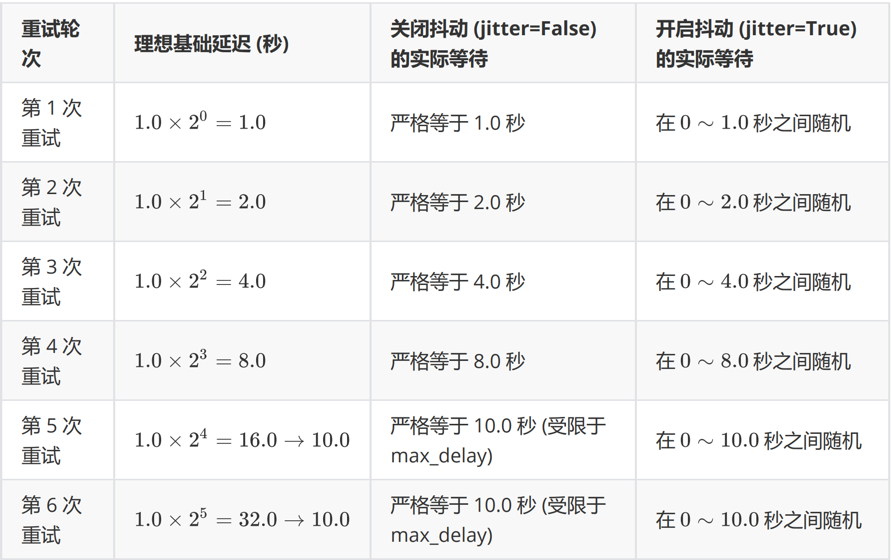

2. 为什么要引入 Jitter（抖动）？关闭它会有什么问题？

在单用户、单并发的测试环境下，关闭 jitter没有任何副作用，甚至能让等待时间非常规律、可预测。

但在高并发的生产环境中，关闭 jitter会引发灾难性的 “惊群效应（Thundering Herd Problem）” ：
- 没有 Jitter 的惨剧（ jitter=False ）：假设某刻天气 API 服务突然宕机了 1 秒。此时刚好有 1000 个用户同时发起了查询。因为这 1000个请求同时失败，并且它们都严格死板地等待 1 秒、2 秒、4 秒……这意味着，在第 1 秒、第 3 秒、第 7 秒的那个精准的时间点上，这 1000 个请求会整整齐齐地再次同时轰炸服务器。刚刚复活的服务器瞬间又被这波整齐的峰值流量压垮，形成恶性循环。
- 引入 Jitter 的优势（ jitter=True ）：通过给重试时间加上随机性，这 1000 个请求会在 秒、 秒的区间内均匀地错开（削峰填谷）。流量被平摊到了整条时间轴上，服务器就能轻松地分批处理完这些请求。

总结：
- jitter=False （你当前的代码）：重试间隔死板、精准、可预测。适合本地调试、测试重试逻辑是否生效。
- jitter=True ：重试间隔随机、错开、更安全。适合线上生产环境，防止把下游第三方 API 或数据库冲垮。

## 6、ModelRetryMiddleware中间件

模型调用失败时重试，策略和工具调用的重试一样，都是基于指数退避算法。

```
ModelRetryMiddleware(
  self,
  *,
  max_retries: int = 2,
  retry_on: RetryOn = default_retry_on,
  on_failure: OnFailure = 'continue',
  backoff_factor: float = 2.0,
  initial_delay: float = 1.0,
  max_delay: float = 60.0,
  jitter: bool = True
)
```

## 7、LLMToolEmulator中间件

某些情况下，工具尚未开发完成，我们希望先测试工具调用，可以用LLM tool emulator模拟工具。
```
LLMToolEmulator(
  self,
  *,
  tools: list[str | BaseTool] | None = None,
  model: str | BaseChatModel | None = None
)
```

In [ ]:
from langchain.agents.middleware import LLMToolEmulator
from langchain.messages import HumanMessage
import os
from langchain_core.tools import tool
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model

@tool
def get_weather(city: str):
    """查询指定城市天气"""
    return f"{city}今天天气晴朗"

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL")
)

agent = create_agent(
    model=model,
    tools=[get_weather],
    middleware=[
        LLMToolEmulator(
            model=model,
            tools=[get_weather]
        )
    ]
)
response = agent.invoke({
    "messages": [HumanMessage("今天北京天气如何")]
})

for msg in response["messages"]:
    msg.pretty_print()

## 8、ContextEditingMiddleware中间件

上下文编辑中间件，该中间件提供了上下文管理的一种方式。通过更改发送给模型的消息列表来控制成本。

注意：不会改消息列表。因为我们只能通过token用量来推测是否对消息列表进行了裁剪。

```
ContextEditingMiddleware(
  self,
  *,
  edits: Iterable[ContextEdit] | None = None,
  token_count_method: Literal['approximate', 'model'] = 'approximate',
  token_counter: TokenCounter | None = None
)
```

### 8.1 启用上下文编辑

In [22]:
from langchain.agents import create_agent
from langchain.agents.middleware import ContextEditingMiddleware, ClearToolUsesEdit
from langchain.messages import HumanMessage, AIMessage
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv

load_dotenv()
count = 0

@tool
def get_weather(city: str):
    """查询指定城市天气"""
    global count
    return (f"当前是第 {count} 次调用工具，{city}今天天气晴朗"
        f"天气非常好，北风，非常适合出行，盼望着，盼望着，"
        f"春天来了。我喜欢春天，你喜欢吗，天气真的很不错"
        f"万里无云，天气晴朗，春和景明，哈哈哈哈哈哈，这是凑字数的"
        f"真不错，天气非常好，适合出行，这里token挺多的"
        f"可以出门玩，尅有跑步，钓鱼，爬山，一切都很好哈哈哈")

agent = create_agent(
    model=model,
    tools=[get_weather],
    middleware=[
        ContextEditingMiddleware(
            edits=[
                ClearToolUsesEdit(
                    trigger=50,  # token用量达到50触发
                    keep=0   # 保留最近几条信息
                )
            ]
        )
    ],
    checkpointer=InMemorySaver()
)

config = {"configurable": {"thread_id": "1"}}
for i in range(3):
    print("=" * 30, f"当前是第 {i + 1} 轮调用", "=" * 30)
    count = i + 1
    response = agent.invoke({
        "messages": [HumanMessage(f"第 {i + 1} 次询问：今天北京天气如何，一句话回答")]},
        config=config
    )

    print("---- 本次返回的 messages ----")
    for msg in response["messages"]:
        # msg.pretty_print()
        if isinstance(msg, AIMessage):
            if not msg.tool_calls:
                print(f"本次token用量：{msg.usage_metadata}")

============================== 当前是第 1 轮调用 ==============================
---- 本次返回的 messages ----
本次token用量：{'input_tokens': 367, 'output_tokens': 93, 'total_tokens': 460, 'input_token_details': {'cache_read': 128}, 'output_token_details': {'reasoning': 64}}
============================== 当前是第 2 轮调用 ==============================
---- 本次返回的 messages ----
本次token用量：{'input_tokens': 367, 'output_tokens': 93, 'total_tokens': 460, 'input_token_details': {'cache_read': 128}, 'output_token_details': {'reasoning': 64}}
本次token用量：{'input_tokens': 468, 'output_tokens': 33, 'total_tokens': 501, 'input_token_details': {'cache_read': 256}, 'output_token_details': {'reasoning': 0}}
============================== 当前是第 3 轮调用 ==============================
---- 本次返回的 messages ----
本次token用量：{'input_tokens': 367, 'output_tokens': 93, 'total_tokens': 460, 'input_token_details': {'cache_read': 128}, 'output_token_details': {'reasoning': 64}}
本次token用量：{'input_tokens': 468, 'output_tokens': 33, 'total_tok

说明：
1. ContextEditingMiddleware 的价值：大模型多轮对话时，如果频繁调用产生大量文本的工具（如代码执行、网页爬取），历史记录会急剧膨胀。这个中间件就像一个“上下文抽脂手术”，在不影响当前对话的前提下，自动在后台删掉之前沉淀的工具调用废话，从而极大地节省 Token 费用并防止超出模型最大上下文窗口（Context Window）。
2. InMemorySaver ：它在内存中开辟了一个空间。第二轮和第三轮提问时，Agent 能通过thread_id 自动找回前几轮的记忆。

### 8.2 不裁剪上下文

In [23]:
from langchain.agents import create_agent
from langchain.messages import HumanMessage, AIMessage
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv

load_dotenv()
count = 0

@tool
def get_weather(city: str):
    """查询指定城市天气"""
    global count
    return (f"当前是第 {count} 次调用工具，{city}今天天气晴朗"
        f"天气非常好，北风，非常适合出行，盼望着，盼望着，"
        f"春天来了。我喜欢春天，你喜欢吗，天气真的很不错"
        f"万里无云，天气晴朗，春和景明，哈哈哈哈哈哈，这是凑字数的"
        f"真不错，天气非常好，适合出行，这里token挺多的"
        f"可以出门玩，尅有跑步，钓鱼，爬山，一切都很好哈哈哈")

agent = create_agent(
    model=model,
    tools=[get_weather],
    checkpointer=InMemorySaver()
)

config = {"configurable": {"thread_id": "1"}}
for i in range(3):
    print("=" * 30, f"当前是第 {i + 1} 轮调用", "=" * 30)
    count = i + 1
    response = agent.invoke({
        "messages": [HumanMessage(f"第 {i + 1} 次询问：今天北京天气如何，一句话回答")]},
        config=config
    )

    print("---- 本次返回的 messages ----")
    for msg in response["messages"]:
        # msg.pretty_print()
        if isinstance(msg, AIMessage):
            if not msg.tool_calls:
                print(f"本次token用量：{msg.usage_metadata}")

============================== 当前是第 1 轮调用 ==============================
---- 本次返回的 messages ----
本次token用量：{'input_tokens': 453, 'output_tokens': 38, 'total_tokens': 491, 'input_token_details': {'cache_read': 256}, 'output_token_details': {'reasoning': 17}}
============================== 当前是第 2 轮调用 ==============================
---- 本次返回的 messages ----
本次token用量：{'input_tokens': 453, 'output_tokens': 38, 'total_tokens': 491, 'input_token_details': {'cache_read': 256}, 'output_token_details': {'reasoning': 17}}
本次token用量：{'input_tokens': 480, 'output_tokens': 111, 'total_tokens': 591, 'input_token_details': {'cache_read': 256}, 'output_token_details': {'reasoning': 93}}
============================== 当前是第 3 轮调用 ==============================
---- 本次返回的 messages ----
本次token用量：{'input_tokens': 453, 'output_tokens': 38, 'total_tokens': 491, 'input_token_details': {'cache_read': 256}, 'output_token_details': {'reasoning': 17}}
本次token用量：{'input_tokens': 480, 'output_tokens': 111, 'total_

## 9、FilesystemFileSearchMiddleware中间件

基于系统的Glob和Grep检索工具，为Agent赋予本地文件搜索和分析的能力。
- Glob根据文件路径检索
- Grep根据文件内容检索

```
FilesystemFileSearchMiddleware(
  self,
  *,
  root_path: str,
  use_ripgrep: bool = True,
  max_file_size_mb: int = 10
)
```

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import FilesystemFileSearchMiddleware
from langchain.messages import HumanMessage

agent = create_agent(
    model=model,
    tools=[], # 自动添加Glob和Grep工具
    middleware=[
        FilesystemFileSearchMiddleware(
            root_path="./",  # 搜索目录
            # 【可选】限制搜索的文件后缀，防止模型读取非代码或无关文件
            # allowed_extensions=[".py", ".ipynb", ".js", ".md"], # 允许的文件类型
            # 是否启用 ripgrep 搜索引擎：
            # 设为 True 可以获得比原生 Grep 更快的性能（前提是系统已安装 ripgrep）
            use_ripgrep=True,
            # 单个文件的最大读取限制（单位MB）：防止读取超大型日志或二进制文件导致 OOM
            max_file_size_mb=10
        )
    ]
)

result = agent.invoke({
    "messages": [HumanMessage("找到包含add函数的Python或Jupyter文件")]
})

for msg in result["messages"]:
    msg.pretty_print()

## 10、Shell tool中间件

为Agent提供一个可以执行命令的Shell环境。

该中间件提供一个长期运行的 Shell 会话。您可以根据部署环境的安全需求，选择合适的执行策略（Execution Policy）：

- HostExecutionPolicy —— 默认选项，允许完全访问宿主机；适用于受信任的环境，且智能体已在提供隔离机制的容器或虚拟机中运行。
- CodexSandboxExecutionPolicy —— 在 Codex CLI 可用的情况下，复用其沙箱环境，从而对系统调用（syscall）和文件系统施加额外限制。
- DockerExecutionPolicy —— 为每次智能体运行启动一个独立的 Docker 容器，提供更强的隔离性，支持配置只读根文件系统，并可进行用户映射（User Remapping）。

```
ShellToolMiddleware(
  self,
  workspace_root: str | Path | None = None,
  *,
  startup_commands: tuple[str, ...] | list[str] | str | None = None,
  shutdown_commands: tuple[str, ...] | list[str] | str | None = None,
  execution_policy: BaseExecutionPolicy | None = None,
  redaction_rules: tuple[RedactionRule, ...] | list[RedactionRule] | None = None,
  tool_description: str | None = None,
  tool_name: str = SHELL_TOOL_NAME,
  shell_command: Sequence[str] | str | None = None,
  env: Mapping[str, Any] | None = None
)
```

In [25]:
from langchain.agents import create_agent
from langchain.agents.middleware import ShellToolMiddleware, HostExecutionPolicy
from langchain.messages import HumanMessage

agent = create_agent(
    model=model,
    middleware=[
        ShellToolMiddleware(
            workspace_root="./",
            execution_policy=HostExecutionPolicy()
        )
    ]
)

result = agent.invoke({
    "messages": [HumanMessage("列出当前目录下的所有文件")]
})

for msg in result["messages"]:
    msg.pretty_print()

================================ Human Message =================================

列出当前目录下的所有文件
================================== Ai Message ==================================
Tool Calls:
  shell (call_00_py0GQMseoX2FMrFxoep13507)
 Call ID: call_00_py0GQMseoX2FMrFxoep13507
  Args:
    command: pwd && ls -la
================================= Tool Message =================================
Name: shell

/Users/lxp/Documents/学习笔记/learnNote/AI/LangChain/langchain1.2-tutorial/4-中间件Middleware
total 1760
drwxr-xr-x@  7 lxp  staff     224 Nov 15 22:27 .
drwxr-xr-x@ 13 lxp  staff     416 Nov 13 16:17 ..
-rw-r--r--@  1 lxp  staff  579934 Nov 10 21:49 1-中间件概述.ipynb
-rw-r--r--@  1 lxp  staff   35130 Nov 13 17:33 2-常用内置中间件使用.ipynb
-rw-r--r--@  1 lxp  staff  273464 Nov 15 22:27 3-其他内置中间件.ipynb
-rw-r--r--@  1 lxp  staff    1330 Nov 15 20:57 call_times_with_jitter.txt
-rw-r--r--@  1 lxp  staff    2011 Nov 15 21:02 call_times_with_no_jitter.txt

================================== Ai Message =============

## 11、Filesystem中间件

这是源自deepagents（基于LangChain的另一个框架）的中间件，内置了四个工具，分别用于查看目录、读文件、写文件和改文件。

## 12、Subagent中间件

也是来自deepagents的中间件，用于便捷地创建子Agent。

```
from deepagents.backends import StateBackend
from deepagents.middleware.subagents import SubAgentMiddleware
from langchain.agents import create_agent
from langchain.tools import tool


@tool
def get_weather(city: str) -> str:
    """Get the weather in a city."""
    return f"The weather in {city} is sunny."


agent = create_agent(
    model="openai:gpt-6.1-sol",
    middleware=[
        SubAgentMiddleware(
            backend=StateBackend(),
            subagents=[
                {
                    "name": "weather",
                    "description": "This subagent can get weather in cities.",
                    "system_prompt": (
                        "Use the get_weather tool to get the weather in a city."
                    ),
                    "tools": [get_weather],
                    "model": "gpt-6.1-sol",
                    "middleware": [],
                }
            ],
        )
    ],
)
```